# Tutorial · Build our six-model forecast ensemble

**Workshop: Many models, one forecast** · about 25 minutes · runs on a laptop CPU, no GPU and no training needed.

**The project need.** Our sea-temperature forecasting models are noisy: retrain the same network with a new random seed and its score moves. A final submission should not depend on a lucky seed.

**What you will produce.** Starting from six networks we already trained (2 architectures × 3 random seeds), you will:

| Step | You do | Checkpoint: you should see |
|---|---|---|
| 0 | Check your setup | `Setup OK` |
| 1 | Load the data and score the baseline | `X: (728, 14, 12, 14)`, persistence `0.3075` |
| 2 | Run the six trained networks | six scores between `0.2747` and `0.2805` |
| 3 | **Deep ensemble**: average the 3 seeds of each network | `0.2738` and `0.2743` |
| 4 | **Averaging**: combine the two architectures 50/50 | `0.2685` |
| 5 | Measure *why* it works: error correlation | `0.963` vs `0.898` |
| 6 | **Your turn**: pick your own 3-model ensemble and explain the result | your score and its rank out of 20 |

**How to use this notebook.** Run the cells from top to bottom with **Shift + Enter**. After each step, compare your output with the ✅ checkpoint. The notebook is saved with outputs, so you can also just read it. Stuck? See *Troubleshooting* in the README, or raise your hand.

After step 6, continue with **Part 4** in `02_other_ensemble_methods.ipynb` (bagging, boosting, stacking). The bonus sections at the end of this notebook go deeper; they are optional.

## Step 0 · Setup check

This cell imports the libraries and our helper module `sst_models.py` (the two network architectures, checkpoint loading and the scoring metric), and checks that the six checkpoints are where the notebook expects them.

In [1]:
import sys
sys.path.insert(0, "..")            # sst_models.py lives one folder up
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sst_models import load_checkpoint, predict, score, rmse_per_day

ckpts = sorted(Path("../checkpoints").glob("*.pt"))
print(f"torch {torch.__version__}, {len(ckpts)} checkpoints found")
assert len(ckpts) == 6, "Checkpoints not found: open this notebook from the notebooks/ folder"
print("Setup OK")

torch 2.2.2, 6 checkpoints found
Setup OK


In [2]:
# Plot settings (nothing to change here)
BLUE, ORANGE, NAVY, GREY = "#1F6F9F", "#C55A23", "#12263A", "#8A94A3"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 4)

✅ **Checkpoint 0:** `torch 2.2.2, 6 checkpoints found` and `Setup OK`. A different torch 2.x version is fine.

## Step 1 · Load the data and score the baseline

The competition gives us **14 daily sea-surface temperature (SST) maps** on a 12 × 14 grid around the Florida Keys, and asks for the **next 3 days**. Only ocean cells are scored (`mask`). We use the validation split: 728 examples from 2022–2023.

In [3]:
with np.load("../data/validation.npz") as data:
    X, y = data["X"], data["y"]
    mask = data["mask"].astype(bool)
    dates = data["dates"].astype(str)
    lat, lon = data["lat"], data["lon"]

print("X:", X.shape)    # (examples, 14 input days, lat, lon)
print("y:", y.shape)    # (examples, 3 forecast days, lat, lon)
print("ocean cells:", mask.sum(), "of", mask.size)

X: (728, 14, 12, 14)
y: (728, 3, 12, 14)
ocean cells: 143 of 168


✅ **Checkpoint 1a:** `X: (728, 14, 12, 14)`, `y: (728, 3, 12, 14)`, `ocean cells: 143 of 168`.

One example, to see what the model gets and what it must predict:

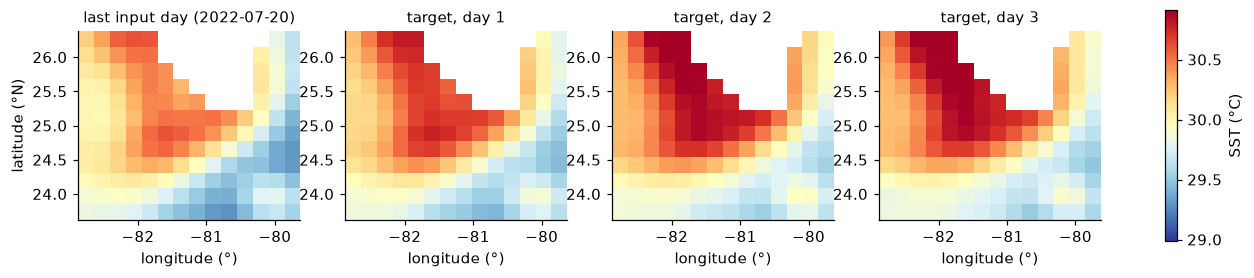

In [4]:
lon = np.where(lon > 180, lon - 360, lon)            # 0-360 °E -> -180..180
extent = [lon.min(), lon.max(), lat.min(), lat.max()]
show = lambda a: np.where(mask, a, np.nan)           # hide land

i = 200
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
panels = [(X[i, -1], f"last input day ({dates[i]})")] + [(y[i, d], f"target, day {d + 1}") for d in range(3)]
vmin, vmax = np.nanmin(show(X[i, -1])) - .3, np.nanmax(show(X[i, -1])) + .3
for ax, (field, title) in zip(axes, panels):
    im = ax.imshow(show(field), origin="lower", extent=extent, cmap="RdYlBu_r", vmin=vmin, vmax=vmax)
    ax.set_title(title, fontsize=10); ax.set_xlabel("longitude (°)")
axes[0].set_ylabel("latitude (°N)")
fig.colorbar(im, ax=axes, label="SST (°C)", shrink=.85)
plt.show()

The bar to beat is **persistence**: "the next three days look like today". The score is the RMSE in °C over ocean cells, averaged over the 3 forecast days (lower is better).

In [5]:
persistence = np.repeat(X[:, -1:], 3, axis=1)        # copy the last day 3 times
print(f"persistence RMSE: {score(persistence, y, mask):.4f} °C")

persistence RMSE: 0.3075 °C


✅ **Checkpoint 1b:** `persistence RMSE: 0.3075 °C`.

## Step 2 · Run the six trained networks

Our two best architectures, each trained three times with identical settings except the random seed (444, 445, 446):

* **Flattened TCN** (`tcn`): each map becomes a 168-value vector; a temporal convolutional network reads the 14 days. Sees the whole box at once.
* **Spatial TCN** (`spatial_tcn`): image-style convolutions on each day, then one small TCN shared by every grid cell.

`predict` returns one forecast per example: shape `(728, 3, 12, 14)`, the same as `y`. All six take about 30 seconds on a laptop CPU.

In [6]:
FAMILIES = ["tcn", "spatial_tcn"]
SEEDS = [444, 445, 446]

preds = {}
for family in FAMILIES:          # tcn, spatial_tcn
    for seed in SEEDS:           # 444, 445, 446
        path = f"../checkpoints/{family}_seed{seed}.pt"
        _, model = load_checkpoint(path)
        preds[(family, seed)] = predict(model, X)

for key, p in preds.items():
    print(key, p.shape, f"{score(p, y, mask):.4f}")

('tcn', 444) (728, 3, 12, 14) 0.2788
('tcn', 445) (728, 3, 12, 14) 0.2781
('tcn', 446) (728, 3, 12, 14) 0.2763
('spatial_tcn', 444) (728, 3, 12, 14) 0.2805
('spatial_tcn', 445) (728, 3, 12, 14) 0.2794
('spatial_tcn', 446) (728, 3, 12, 14) 0.2747


✅ **Checkpoint 2:** six lines, each with shape `(728, 3, 12, 14)` and a score between `0.2747` and `0.2805`. Every network beats persistence (0.3075).

The same numbers per forecast day:

In [7]:
def row(name, p):
    d = rmse_per_day(p, y, mask)
    return {"model": name, "day 1": d[0], "day 2": d[1], "day 3": d[2], "mean RMSE": d.mean()}

singles = pd.DataFrame([row(f"{f}, seed {s}", p) for (f, s), p in preds.items()])
singles

,model,day 1,day 2,day 3,mean RMSE
0,"tcn, seed 444",0.1546,0.2873,0.3943,0.2788
1,"tcn, seed 445",0.1550,0.2869,0.3924,0.2781
2,"tcn, seed 446",0.1567,0.2851,0.3872,0.2763
3,"spatial_tcn, seed 444",0.1566,0.2896,0.3952,0.2805
4,"spatial_tcn, seed 445",0.1530,0.2888,0.3965,0.2794
5,"spatial_tcn, seed 446",0.1495,0.2836,0.3911,0.2747


**Seed luck is real.** Same code, same data, only the seed changed, and the score moves by up to 0.006 °C. That is bigger than the gap between the two architectures, so a single run cannot tell us which model is better. (Seed 446 looks best for both because we tuned every hyperparameter with seed 446.)

## Step 3 · Deep ensemble: average the seeds

A **deep ensemble** trains the same network with different random seeds and averages the forecasts. Each seed starts from different weights and sees the batches in a different order, so each run makes slightly different mistakes, and averaging cancels part of them.

`np.mean(..., axis=0)` averages the three forecasts cell by cell: three arrays of shape `(728, 3, 12, 14)` in, one of the same shape out.

In [8]:
family_mean = {
    f: np.mean([preds[(f, s)] for s in SEEDS], axis=0)
    for f in FAMILIES
}
for f in FAMILIES:
    print(f, f"{score(family_mean[f], y, mask):.4f}")

tcn 0.2738
spatial_tcn 0.2743


✅ **Checkpoint 3:** `tcn 0.2738` and `spatial_tcn 0.2743`. A typical single run scores about 0.278, so averaging three seeds took off about 0.004 °C, with no new model and no tuning.

## Step 4 · Averaging: combine the two architectures

Now average the two seed-averages 50/50. For numbers like temperatures, "voting" simply means taking the mean. We fixed the weights at 50/50 **before** looking at the validation score, so the score stays honest.

In [9]:
ensemble = np.mean([family_mean[f] for f in FAMILIES], axis=0)
print(f"all six, 50/50: {score(ensemble, y, mask):.4f}")

all six, 50/50: 0.2685


✅ **Checkpoint 4:** `all six, 50/50: 0.2685`. This is the forecast behind our best Kaggle submission (public score 0.27419, against 0.28150 for our best single TCN).

Every step side by side, per forecast day:

In [10]:
steps = pd.DataFrame([
    row("persistence", persistence),
    {**row("single model (average over 6 runs)", ensemble), **singles[["day 1", "day 2", "day 3", "mean RMSE"]].mean().to_dict()},
    row("best single run (spatial, seed 446)", preds[("spatial_tcn", 446)]),
    row("flattened TCN × 3 seeds", family_mean["tcn"]),
    row("spatial TCN × 3 seeds", family_mean["spatial_tcn"]),
    row("all six, 50/50", ensemble),
]).set_index("model")
steps

,day 1,day 2,day 3,mean RMSE
model,,,,
persistence,0.1792,0.3171,0.4262,0.3075
single model (average over 6 runs),0.1542,0.2869,0.3928,0.2780
"best single run (spatial, seed 446)",0.1495,0.2836,0.3911,0.2747
flattened TCN × 3 seeds,0.1522,0.2824,0.3868,0.2738
spatial TCN × 3 seeds,0.1497,0.2835,0.3899,0.2743
"all six, 50/50",0.1474,0.2770,0.3811,0.2685


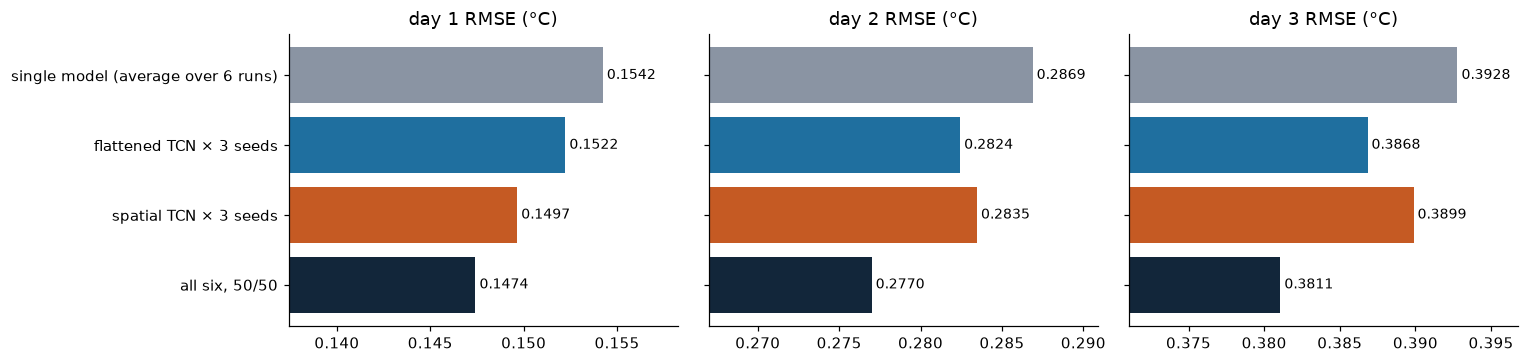

In [11]:
show_rows = ["single model (average over 6 runs)", "flattened TCN × 3 seeds", "spatial TCN × 3 seeds", "all six, 50/50"]
colors = [GREY, BLUE, ORANGE, NAVY]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
for ax, day in zip(axes, ["day 1", "day 2", "day 3"]):
    vals = steps.loc[show_rows, day]
    ax.barh(range(4), vals, color=colors)
    ax.set_yticks(range(4), show_rows if day == "day 1" else [""] * 4)
    ax.set_xlim(vals.min() - .01, vals.max() + .004); ax.invert_yaxis()
    for k, v in enumerate(vals):
        ax.text(v, k, f" {v:.4f}", va="center", fontsize=9)
    ax.set_title(f"{day} RMSE (°C)")
plt.tight_layout(); plt.show()

The six-model ensemble beats every single run, including the lucky one, **on every forecast day**.

## Step 5 · Why mixing architectures wins: error correlation

From the slides: averaging only removes the part of the error that models **don't share**. The error correlation ρ measures how much they share (1 = identical mistakes). Let's measure it for every pair of models, over every ocean cell, example and day.

In [12]:
keys = list(preds)
errors = np.array([(preds[k] - y)[:, :, mask].ravel()
                   for k in keys])      # (6, all errors)
corr = np.corrcoef(errors)              # (6, 6)

same = [corr[a, b] for a in range(6) for b in range(a + 1, 6) if keys[a][0] == keys[b][0]]
cross = [corr[a, b] for a in range(6) for b in range(a + 1, 6) if keys[a][0] != keys[b][0]]
print(f"ρ, same architecture, different seed: {np.mean(same):.3f}")
print(f"ρ, different architectures:           {np.mean(cross):.3f}")

ρ, same architecture, different seed: 0.963
ρ, different architectures:           0.898


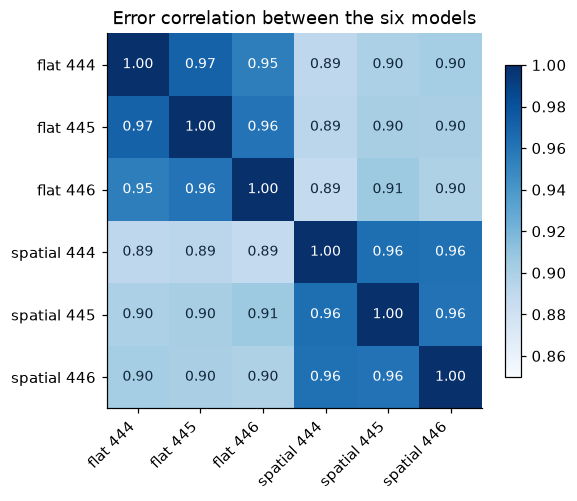

In [13]:
labels = [f"{'flat' if f == 'tcn' else 'spatial'} {s}" for f, s in keys]
fig, ax = plt.subplots(figsize=(5.5, 4.6))
im = ax.imshow(corr, cmap="Blues", vmin=.85, vmax=1)
ax.set_xticks(range(6), labels, rotation=45, ha="right"); ax.set_yticks(range(6), labels)
for a in range(6):
    for b in range(6):
        ax.text(b, a, f"{corr[a, b]:.2f}", ha="center", va="center", fontsize=9, color="white" if corr[a, b] > .95 else NAVY)
ax.set_title("Error correlation between the six models")
fig.colorbar(im, shrink=.8); plt.show()

✅ **Checkpoint 5:** `0.963` for seeds of the same architecture, `0.898` across architectures.

Seeds of one network think alike; a different architecture makes more different mistakes. That is why mixing architectures (step 4) gained more than adding seeds (step 3).

---

## Step 6 · Your turn: you can afford three trainings

**Scenario.** On the next project, your team only has compute for **three** training runs. Which three of our six models would you ensemble?

1. Edit `my_pick` below: choose any 3 of `("tcn", 444)`, `("tcn", 445)`, `("tcn", 446)`, `("spatial_tcn", 444)`, `("spatial_tcn", 445)`, `("spatial_tcn", 446)`.
2. Run the cell, then run the check cell under it.
3. Try at least two different picks, including one that mixes both architectures.
4. Write your answer in the last cell: **what changed, and why?** Use ρ from step 5.

In [14]:
# ✏️ Edit this list: any 3 of the 6 models
my_pick = [("tcn", 444), ("tcn", 445), ("tcn", 446)]

my_ensemble = np.mean([preds[k] for k in my_pick], axis=0)
print(f"your ensemble: {score(my_ensemble, y, mask):.4f}")

your ensemble: 0.2738


In [15]:
# ✅ Check your result (no need to edit)
import itertools

all3 = {c: score(np.mean([preds[k] for k in c], axis=0), y, mask) for c in itertools.combinations(keys, 3)}
mine = score(my_ensemble, y, mask)
mixed = len({f for f, _ in my_pick}) == 2

print(f"your score {mine:.4f}: rank {1 + sum(v < mine - 1e-9 for v in all3.values())} of {len(all3)}")
print("mixes both architectures:", "yes" if mixed else "no")
print(f"average of one-architecture picks: {np.mean([v for c, v in all3.items() if len({f for f, _ in c}) == 1]):.4f}")
print(f"average of mixed picks:            {np.mean([v for c, v in all3.items() if len({f for f, _ in c}) == 2]):.4f}")
print(f"best possible pick:                {min(all3.values()):.4f}")

your score 0.2738: rank 19 of 20
mixes both architectures: no
average of one-architecture picks: 0.2741
average of mixed picks:            0.2700
best possible pick:                0.2685


✅ **What a reasonable result looks like:** an all-`tcn` or all-`spatial_tcn` pick scores about `0.274`; a pick that mixes both architectures scores between `0.2685` and `0.2714` and lands near the top of the ranking. Any mixed pick beats both one-architecture picks.

**Stretch (if you finish early):** replace `np.mean` with `np.median` in your cell, or try a 2-model ensemble. Does the ranking change?

**Your answer** (double-click to edit): *What changed between your picks, and why? Hint: compare the ρ values from step 5.*

---

# Bonus sections (optional, after the workshop)

## B1 · Does it depend on picking the lucky models?

All 9 pairs of one flattened + one spatial model:

In [16]:
SEED_PAIRS = [(a, b) for a in SEEDS for b in SEEDS]
pairs = pd.Series({f"flat {a} + spatial {b}": score((preds[("tcn", a)] + preds[("spatial_tcn", b)]) / 2, y, mask)
                   for a, b in SEED_PAIRS}).sort_values()
six = score(ensemble, y, mask)
print(f"pairs: {pairs.mean():.4f} ± {pairs.std():.4f}  (range {pairs.min():.4f} to {pairs.max():.4f})")
print(f"all six: {six:.4f}, better than {(pairs > six).sum()} of 9 pairs")
pairs.to_frame("mean RMSE")

pairs: 0.2705 ± 0.0013  (range 0.2681 to 0.2718)
all six: 0.2685, better than 8 of 9 pairs


,mean RMSE
flat 446 + spatial 446,0.2681
flat 445 + spatial 446,0.2692
flat 444 + spatial 446,0.2697
flat 446 + spatial 444,0.2699
flat 446 + spatial 445,0.2711
flat 445 + spatial 444,0.2714
flat 445 + spatial 445,0.2715
flat 444 + spatial 444,0.2716
flat 444 + spatial 445,0.2718


The best pair is the "lucky" one where both models use seed 446. The six-model ensemble beats the other eight without depending on luck.

## B2 · Every possible subset

Average any subset of the six models (63 subsets), colored by whether it mixes architectures:

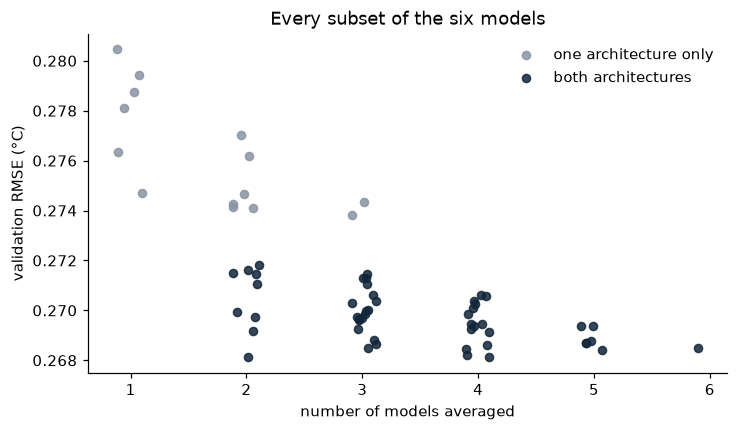

mixed,one architecture,both
size,,
1,0.2780,NaN
2,0.2751,0.2705
3,0.2741,0.2700
4,NaN,0.2695
5,NaN,0.2689
6,NaN,0.2685


In [17]:
subsets = []
for k in range(1, 7):
    for combo in itertools.combinations(keys, k):
        subsets.append({"size": k, "mixed": len({f for f, _ in combo}) == 2,
                        "rmse": score(np.mean([preds[c] for c in combo], axis=0), y, mask)})
subsets = pd.DataFrame(subsets)

fig, ax = plt.subplots(figsize=(7.5, 4))
jitter = np.random.default_rng(0).uniform(-.12, .12, len(subsets))
for is_mixed, color, name in [(False, GREY, "one architecture only"), (True, NAVY, "both architectures")]:
    s = subsets[subsets.mixed == is_mixed]
    ax.scatter(s["size"] + jitter[s.index], s["rmse"], color=color, s=28, label=name, alpha=.85)
ax.set_xlabel("number of models averaged"); ax.set_ylabel("validation RMSE (°C)")
ax.set_title("Every subset of the six models"); ax.legend(frameon=False)
plt.show()
subsets.groupby(["size", "mixed"])["rmse"].mean().unstack().rename(columns={False: "one architecture", True: "both"})

At every size, the subsets that mix architectures are clearly better: two different models beat three copies of the same one.

## B3 · Should we have tuned the 50/50 weight?

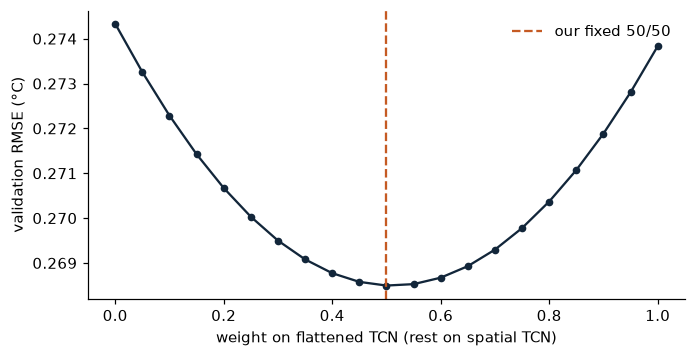

best weight on validation: 0.50 -> 0.2685   vs 50/50: 0.2685


In [18]:
ws = np.linspace(0, 1, 21)
sweep = [score(w * family_mean["tcn"] + (1 - w) * family_mean["spatial_tcn"], y, mask) for w in ws]

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(ws, sweep, "o-", color=NAVY, ms=4)
ax.axvline(.5, color=ORANGE, ls="--", label="our fixed 50/50")
ax.set_xlabel("weight on flattened TCN (rest on spatial TCN)"); ax.set_ylabel("validation RMSE (°C)"); ax.legend(frameon=False)
plt.show()
print(f"best weight on validation: {ws[int(np.argmin(sweep))]:.2f} -> {min(sweep):.4f}   vs 50/50: {sweep[10]:.4f}")

The curve is flat around 0.5. Tuning on the same data we report would also make the report optimistic. An honest way to tune: pick the weight on 2022 and evaluate it on 2023.

In [19]:
first = np.char.startswith(dates, "2022"); second = ~first
def half_score(w, rows):
    return score(w * family_mean["tcn"][rows] + (1 - w) * family_mean["spatial_tcn"][rows], y[rows], mask)

w_tuned = ws[int(np.argmin([half_score(w, first) for w in ws]))]
print(f"weight tuned on 2022: {w_tuned:.2f}")
print(f"on 2023 -> tuned weight: {half_score(w_tuned, second):.4f}   fixed 50/50: {half_score(.5, second):.4f}")

weight tuned on 2022: 0.50
on 2023 -> tuned weight: 0.2592   fixed 50/50: 0.2592


Tuning on 2022 lands right back on 0.50: equal weights were the right call.

## B4 · Why it works: the ambiguity decomposition

For a simple average under squared error there is an exact identity (Krogh & Vedelsby, 1995):

$$\underbrace{\text{MSE}(\bar f)}_{\text{ensemble}} \;=\; \underbrace{\overline{\text{MSE}(f_i)}}_{\text{average member}} \;-\; \underbrace{\overline{(f_i - \bar f)^2}}_{\text{diversity}}$$

The ensemble is always at least as good as the average member, and the gain is exactly how much the members disagree.

In [20]:
members = np.array([preds[k][:, :, mask] for k in keys])            # (6, examples, days, ocean cells)
target, avg = y[:, :, mask], members.mean(axis=0)

avg_member_mse = ((members - target) ** 2).mean()
diversity = ((members - avg) ** 2).mean()
ensemble_mse = ((avg - target) ** 2).mean()

print(f"average member MSE   {avg_member_mse:.5f}")
print(f"- diversity          {diversity:.5f}")
print(f"= ensemble MSE       {avg_member_mse - diversity:.5f}   (computed directly: {ensemble_mse:.5f})")
print(f"\ndiversity removed {diversity / avg_member_mse:.1%} of the average member's squared error")

average member MSE   0.08680
- diversity          0.00557
= ensemble MSE       0.08123   (computed directly: 0.08123)

diversity removed 6.4% of the average member's squared error


## B5 · Where on the map does it help, and what does disagreement tell us?

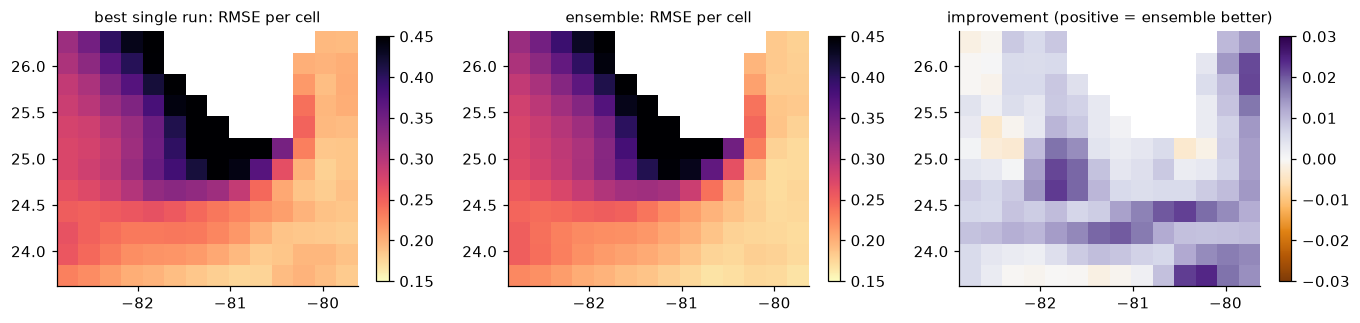

ensemble is better in 88% of ocean cells


In [21]:
def cell_rmse(p):
    return np.sqrt(((p - y) ** 2).mean(axis=(0, 1)))               # RMSE per grid cell

best_single = cell_rmse(preds[("spatial_tcn", 446)])
ens_cells = cell_rmse(ensemble)
gain = best_single - ens_cells

fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
for ax, field, title, cmap, lim in [
        (axes[0], best_single, "best single run: RMSE per cell", "magma_r", (0.15, .45)),
        (axes[1], ens_cells, "ensemble: RMSE per cell", "magma_r", (0.15, .45)),
        (axes[2], gain, "improvement (positive = ensemble better)", "PuOr", (-.03, .03))]:
    im = ax.imshow(show(field), origin="lower", extent=extent, cmap=cmap, vmin=lim[0], vmax=lim[1])
    ax.set_title(title, fontsize=10); fig.colorbar(im, ax=ax, shrink=.85)
plt.show()
print(f"ensemble is better in {(gain[mask] > 0).mean():.0%} of ocean cells")

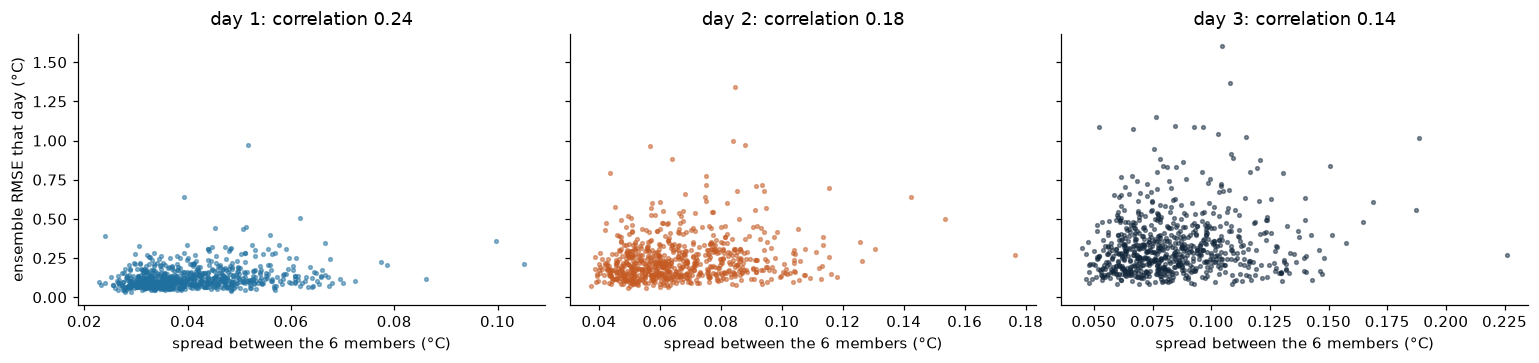

typical spread between members: 0.064 °C   typical ensemble error: 0.232 °C


In [22]:
member_std = members.std(axis=0).mean(axis=-1)                       # (examples, days): disagreement over the map
ens_err = np.sqrt(((avg - target) ** 2).mean(axis=-1))               # (examples, days): ensemble RMSE over the map

fig, axes = plt.subplots(1, 3, figsize=(14, 3.4), sharey=True)
for d, ax in enumerate(axes):
    r = np.corrcoef(member_std[:, d], ens_err[:, d])[0, 1]
    ax.scatter(member_std[:, d], ens_err[:, d], s=6, color=[BLUE, ORANGE, NAVY][d], alpha=.5)
    ax.set_title(f"day {d + 1}: correlation {r:.2f}"); ax.set_xlabel("spread between the 6 members (°C)")
axes[0].set_ylabel("ensemble RMSE that day (°C)")
plt.tight_layout(); plt.show()
print(f"typical spread between members: {member_std.mean():.3f} °C   typical ensemble error: {ens_err.mean():.3f} °C")

The members disagree by about 0.06 °C while the actual errors are about 0.23 °C: the six networks are **overconfident as a group**, because they share most of their errors (ρ ≈ 0.9). Their spread is a hint about uncertainty, not a calibrated estimate.

---

# Hand-off: use it in your own project

**When it is useful:** your model's score changes from run to run (neural networks, deep trees), or you have several good models that work differently. **Limitation:** M models cost M× the training and prediction time, and near-identical members add cost without accuracy.

**The recipe**, for any model with a random seed:

```python
preds = []
for seed in [0, 1, 2]:
    model = train_model(train_data, seed=seed)  # your code
    preds.append(model.predict(X_val))
ensemble = np.mean(preds, axis=0)
# then add a second, different architecture the same way
```

Fix the weights before you look at the validation score (equal weights are a strong default), and check the error correlation before adding a member.

**Learn more:** scikit-learn ensemble guide (https://scikit-learn.org/stable/modules/ensemble.html) · Lakshminarayanan et al., *Simple and Scalable Predictive Uncertainty Estimation using Deep Ensembles*, NeurIPS 2017 (https://arxiv.org/abs/1612.01474) · Krogh & Vedelsby, *Neural Network Ensembles, Cross Validation, and Active Learning*, NIPS 7, 1995.

**Credits:** data from the EGR 444 sea-surface temperature forecasting competition (validation split). Models, checkpoints and code by our team.